<a href="https://colab.research.google.com/github/aymomiy3/Fake_News_Detector/blob/main/Fake_News_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install -U transformers datasets accelerate evaluate scikit-learn pandas numpy matplotlib seaborn yake sentence-transformers

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 6.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 110.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 47.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 128.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 116.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 29.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 118.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.4/91.4 kB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 740.6/740.6 kB 53.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 14.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 360.

In [ ]:
import os, re, time, random, gc
import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix
from IPython.display import display

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    !nvidia-smi

PyTorch: 2.11.0+cu130
CUDA available: True
Device: cuda
GPU: Tesla T4
Wed Oct 14 08:54:27 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   63C    P0             28W /   70W |    3531MiB /  15360MiB |      0%      Default |
|                                         |                        |  

In [ ]:
from urllib.request import urlretrieve

DATA_DIR = "/content/fake_news_data"
os.makedirs(DATA_DIR, exist_ok=True)

fake_url = "https://huggingface.co/datasets/Phoenyx83/ISOT-Fake-News-Dataset-FineTuned-2022/resolve/main/raw/Fake%20ok.csv"
true_url = "https://huggingface.co/datasets/Phoenyx83/ISOT-Fake-News-Dataset-FineTuned-2022/resolve/main/raw/True%20ok%20v2.csv"
fake_path = os.path.join(DATA_DIR, "Fake.csv")
true_path = os.path.join(DATA_DIR, "True.csv")

if not os.path.exists(fake_path):
    urlretrieve(fake_url, fake_path)
if not os.path.exists(true_path):
    urlretrieve(true_url, true_path)

fake_df = pd.read_csv(fake_path, on_bad_lines="skip")
true_df = pd.read_csv(true_path, on_bad_lines="skip")
print("Fake columns:", fake_df.columns.tolist())
print("True columns:", true_df.columns.tolist())
display(fake_df.head(2))
display(true_df.head(2))

Fake columns: ['type', 'text']
True columns: ['type', 'text']


,type,text
0,1.0,How soon they forget Obama was called out duri...
1,1.0,The Breakfast Club interview started out when ...


,type,text
0,0,The head of a conservative Republican faction ...
1,0,Transgender people will be allowed for the fir...


In [ ]:
def standardize_columns(df, label):
    df = df.copy()
    df.columns = [str(c).strip().lower() for c in df.columns]

    # Look for text and title columns
    text_col = next((c for c in df.columns if c in ["text", "article", "content", "body"]), None)
    title_col = next((c for c in df.columns if c in ["title", "headline"]), None)

    if text_col is None:
        raise ValueError(f"Could not find a text column. Found: {df.columns.tolist()}")

    # If a title column exists, use it; otherwise, default to an empty string
    if title_col is not None:
        title_series = df[title_col].fillna("").astype(str)
    else:
        title_series = pd.Series([""] * len(df), index=df.index)

    out = pd.DataFrame({
        "title": title_series,
        "body": df[text_col].fillna("").astype(str),
        "label": label
    })
    return out

# Re-run your processing pipeline
fake = standardize_columns(fake_df, 1)
real = standardize_columns(true_df, 0)
data = pd.concat([fake, real], ignore_index=True)
data["title"] = data["title"].str.strip()
data["body"] = data["body"].str.strip()
data["text_original"] = (data["title"] + ". " + data["body"]).str.strip()
data = data[data["text_original"].str.len() > 40].drop_duplicates(subset=["text_original"]).reset_index(drop=True)

# Sample and verify
SAMPLE_PER_CLASS = 8000
if SAMPLE_PER_CLASS is not None:
    data = (data.groupby("label", group_keys=False)
                .apply(lambda x: x.sample(min(len(x), SAMPLE_PER_CLASS), random_state=42))
                .reset_index(drop=True))
data = data.sample(frac=1, random_state=42).reset_index(drop=True)

print("Rows:", len(data))
print(data["label"].value_counts().rename(index={0:"real", 1:"fake"}))
display(data[["title", "label", "text_original"]].head())

Rows: 16000
label
fake    8000
real    8000
Name: count, dtype: int64


/tmp/ipykernel_1294/193056318.py:38: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(min(len(x), SAMPLE_PER_CLASS), random_state=42))


,title,label,text_original
0,,1,. Twenty-one-year-old Marquez Tolbert and his ...
1,,0,". U.S. Representative Adam Schiff, the top Dem..."
2,,0,. A majority of Americans are ready to move on...
3,,0,. U.S. President Donald Trump muscled himself ...
4,,1,. There are a ton of potential conflict-of-int...


In [ ]:
import nltk
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
from nltk.tokenize import sent_tokenize
import yake
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

# Multilingual sentence embeddings support more languages than an English-only encoder.
EMBEDDER_NAME = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
embedder = SentenceTransformer(EMBEDDER_NAME, device=str(device))
kw_extractor = yake.KeywordExtractor(lan="en", n=2, top=10)

def rank_and_filter(title, body, keep_ratio=0.5, min_sentences=2, max_sentences=12):
    title = str(title or "").strip()
    body = str(body or "").strip()
    sentences = [s.strip() for s in sent_tokenize(body) if len(s.strip()) >= 20]
    if len(sentences) <= min_sentences:
        return (title + ". " + body).strip(), "", sentences

    # YAKE! is used to identify salient terms; keyword list is retained for inspection.
    try:
        keywords = [kw for kw, score in kw_extractor.extract_keywords(body)]
    except Exception:
        keywords = []

    # Rank sentence relevance to the headline using semantic cosine similarity.
    inputs = [title if title else body[:300]] + sentences
    vectors = embedder.encode(inputs, convert_to_numpy=True, normalize_embeddings=True, show_progress_bar=False)
    sims = vectors[1:] @ vectors[0]

    # Small keyword-overlap bonus makes the keyword-extraction stage operational.
    kw_terms = set()
    for phrase in keywords:
        kw_terms.update(re.findall(r"\w+", phrase.lower()))
    adjusted = []
    for sentence, sim in zip(sentences, sims):
        tokens = set(re.findall(r"\w+", sentence.lower()))
        overlap = len(tokens & kw_terms) / max(1, len(kw_terms))
        adjusted.append(float(sim) + 0.05 * overlap)

    k = max(min_sentences, int(np.ceil(len(sentences) * keep_ratio)))
    k = min(k, max_sentences, len(sentences))
    chosen_idx = sorted(np.argsort(adjusted)[-k:].tolist())
    selected = [sentences[i] for i in chosen_idx]
    filtered = (title + ". " + " ".join(selected)).strip()
    return filtered, "; ".join(keywords), selected

# First run on a small sample to verify the pipeline before processing the full dataset.
DEMO_N = min(100, len(data))
demo_rows = []
for row in data.iloc[:DEMO_N].itertuples(index=False):
    filtered, keywords, selected = rank_and_filter(row.title, row.body)
    demo_rows.append((filtered, keywords))
data.loc[:DEMO_N-1, "text_filtered"] = [x[0] for x in demo_rows]
data.loc[:DEMO_N-1, "keywords"] = [x[1] for x in demo_rows]
display(data.loc[:DEMO_N-1, ["title", "keywords", "text_original", "text_filtered"]].head(2))

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 9.08MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

,title,keywords,text_original,text_filtered
0,,Martin Blackwell; Anthony Gooden; hate crimes;...,. Twenty-one-year-old Marquez Tolbert and his ...,. Twenty-one-year-old Marquez Tolbert and his ...
1,,Representative Adam; Intelligence Committee; H...,". U.S. Representative Adam Schiff, the top Dem...",". U.S. Representative Adam Schiff, the top Dem..."


In [ ]:
# Process all rows; skip rows already processed in the demo.
filtered_texts = [None] * len(data)
keywords_all = [None] * len(data)
for i, row in enumerate(data.itertuples(index=False)):
    if i < DEMO_N:
        filtered_texts[i] = data.loc[i, "text_filtered"]
        keywords_all[i] = data.loc[i, "keywords"]
    else:
        filtered_texts[i], keywords_all[i], _ = rank_and_filter(row.title, row.body)
    if (i + 1) % 500 == 0:
        print(f"Processed {i+1}/{len(data)}")

data["text_filtered"] = filtered_texts
data["keywords"] = keywords_all
data["text_filtered"] = data["text_filtered"].fillna(data["text_original"])
data.to_csv("/content/fake_news_processed.csv", index=False)
print("Saved /content/fake_news_processed.csv")

Processed 500/16000
Processed 1000/16000
Processed 1500/16000
Processed 2000/16000
Processed 2500/16000
Processed 3000/16000
Processed 3500/16000
Processed 4000/16000
Processed 4500/16000
Processed 5000/16000
Processed 5500/16000
Processed 6000/16000
Processed 6500/16000
Processed 7000/16000
Processed 7500/16000
Processed 8000/16000
Processed 8500/16000
Processed 9000/16000
Processed 9500/16000
Processed 10000/16000
Processed 10500/16000
Processed 11000/16000
Processed 11500/16000
Processed 12000/16000
Processed 12500/16000
Processed 13000/16000
Processed 13500/16000
Processed 14000/16000
Processed 14500/16000
Processed 15000/16000
Processed 15500/16000
Processed 16000/16000
Saved /content/fake_news_processed.csv


In [ ]:
train_df, test_df = train_test_split(
    data, test_size=0.2, random_state=SEED, stratify=data["label"]
)
print("Train:", len(train_df), "Test:", len(test_df))
print("Train label proportions:")
print(train_df["label"].value_counts(normalize=True).sort_index())

Train: 12800 Test: 3200
Train label proportions:
label
0    0.5
1    0.5
Name: proportion, dtype: float64


In [ ]:
from datasets import Dataset
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, DataCollatorWithPadding, set_seed
)
import evaluate

MODEL_NAME = "distilbert/distilbert-base-multilingual-cased"
MAX_LENGTH = 128
LEARNING_RATE = 2e-5
BATCH_SIZE = 8
GRAD_ACCUM = 2
EPOCHS = 2  # Increase to 3–5 for final experiments if compute allows.

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def make_hf_dataset(frame, text_col):
    tmp = frame[[text_col, "label"]].rename(columns={text_col: "text"}).copy()
    ds = Dataset.from_pandas(tmp, preserve_index=False)
    def tokenize(batch):
        return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)
    ds = ds.map(tokenize, batched=True, remove_columns=["text"])
    return ds

train_original = make_hf_dataset(train_df, "text_original")
test_original = make_hf_dataset(test_df, "text_original")
train_filtered = make_hf_dataset(train_df, "text_filtered")
test_filtered = make_hf_dataset(test_df, "text_filtered")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    p, r, f1, _ = precision_recall_fscore_support(
        labels, preds, average="binary", pos_label=1, zero_division=0
    )
    return {
        "accuracy": accuracy_score(labels, preds),
        "precision_fake": p,
        "recall_fake": r,
        "f1_fake": f1
    }

def build_model():
    return AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=2, id2label={0:"REAL", 1:"FAKE"},
        label2id={"REAL":0, "FAKE":1}
    )

collator = DataCollatorWithPadding(tokenizer=tokenizer)


config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

Map:   0%|          | 0/12800 [00:00<?, ? examples/s]

Map:   0%|          | 0/3200 [00:00<?, ? examples/s]

Map:   0%|          | 0/12800 [00:00<?, ? examples/s]

Map:   0%|          | 0/3200 [00:00<?, ? examples/s]

In [ ]:
def train_model(train_ds, eval_ds, run_name):
    model = build_model()
    args = TrainingArguments(
        output_dir=f"/content/{run_name}",
        learning_rate=LEARNING_RATE,
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=BATCH_SIZE,
        gradient_accumulation_steps=GRAD_ACCUM,
        num_train_epochs=EPOCHS,
        weight_decay=1e-2,
        warmup_steps=100,
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_steps=100,
        load_best_model_at_end=True,
        metric_for_best_model="eval_f1_fake",
        greater_is_better=True,
        fp16=torch.cuda.is_available(),
        report_to="none",
        seed=SEED
    )
    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_ds,
        eval_dataset=eval_ds,
        processing_class=tokenizer,  # Updated from tokenizer=tokenizer for newer transformers versions
        data_collator=collator,
        compute_metrics=compute_metrics
    )
    trainer.train()
    return trainer

# Baseline: original headline + full article.
baseline_trainer = train_model(train_original, test_original, "baseline_original_text")
baseline_trainer.save_model("/content/fake_news_baseline_model")
tokenizer.save_pretrained("/content/fake_news_baseline_model")

# Proposed pipeline: headline + YAKE/semantic-ranked sentences.
proposed_trainer = train_model(train_filtered, test_filtered, "proposed_filtered_text")
proposed_trainer.save_model("/content/fake_news_proposed_model")
tokenizer.save_pretrained("/content/fake_news_proposed_model")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision Fake,Recall Fake,F1 Fake
1,0.111442,0.076580,0.981250,1.000000,0.962500,0.980892
2,0.048236,0.025538,0.993437,0.991900,0.995000,0.993448


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Epoch,Training Loss,Validation Loss,Accuracy,Precision Fake,Recall Fake,F1 Fake
1,0.080852,0.064590,0.984375,0.994260,0.974375,0.984217
2,0.077372,0.052127,0.988125,0.989348,0.986875,0.988110


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('/content/fake_news_proposed_model/tokenizer_config.json',
 '/content/fake_news_proposed_model/tokenizer.json')

In [ ]:
def evaluate_trainer(trainer, test_ds, frame, text_col, model_name):
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()
    start = time.perf_counter()
    pred_output = trainer.predict(test_ds)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    y_true = pred_output.label_ids
    y_pred = np.argmax(pred_output.predictions, axis=-1)
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="binary", pos_label=1, zero_division=0
    )
    metrics = {
        "model": model_name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_fake": p,
        "recall_fake": r,
        "f1_fake": f1,
        "test_samples": len(y_true),
        "total_predict_seconds": elapsed,
        "avg_latency_ms_per_article": 1000 * elapsed / max(1, len(y_true)),
        "peak_gpu_memory_mb": (torch.cuda.max_memory_allocated() / (1024**2)) if torch.cuda.is_available() else None
    }
    print("\n", model_name)
    print(classification_report(y_true, y_pred, target_names=["REAL", "FAKE"], zero_division=0))
    print("Confusion matrix [REAL, FAKE]:\n", confusion_matrix(y_true, y_pred))
    return metrics

baseline_metrics = evaluate_trainer(
    baseline_trainer, test_original, test_df, "text_original", "Baseline: original text"
)
proposed_metrics = evaluate_trainer(
    proposed_trainer, test_filtered, test_df, "text_filtered", "Proposed: filtered text"
)

results = pd.DataFrame([baseline_metrics, proposed_metrics])
display(results)
results.to_csv("/content/experiment_results.csv", index=False)
print("Saved /content/experiment_results.csv")


 Baseline: original text
              precision    recall  f1-score   support

        REAL       0.99      0.99      0.99      1600
        FAKE       0.99      0.99      0.99      1600

    accuracy                           0.99      3200
   macro avg       0.99      0.99      0.99      3200
weighted avg       0.99      0.99      0.99      3200

Confusion matrix [REAL, FAKE]:
 [[1587   13]
 [   8 1592]]



 Proposed: filtered text
              precision    recall  f1-score   support

        REAL       0.99      0.99      0.99      1600
        FAKE       0.99      0.99      0.99      1600

    accuracy                           0.99      3200
   macro avg       0.99      0.99      0.99      3200
weighted avg       0.99      0.99      0.99      3200

Confusion matrix [REAL, FAKE]:
 [[1583   17]
 [  21 1579]]


,model,accuracy,precision_fake,recall_fake,f1_fake,test_samples,total_predict_seconds,avg_latency_ms_per_article,peak_gpu_memory_mb
0,Baseline: original text,0.993437,0.991900,0.995000,0.993448,3200,7.352332,2.297604,3690.296387
1,Proposed: filtered text,0.988125,0.989348,0.986875,0.988110,3200,9.616826,3.005258,3690.296387


Saved /content/experiment_results.csv


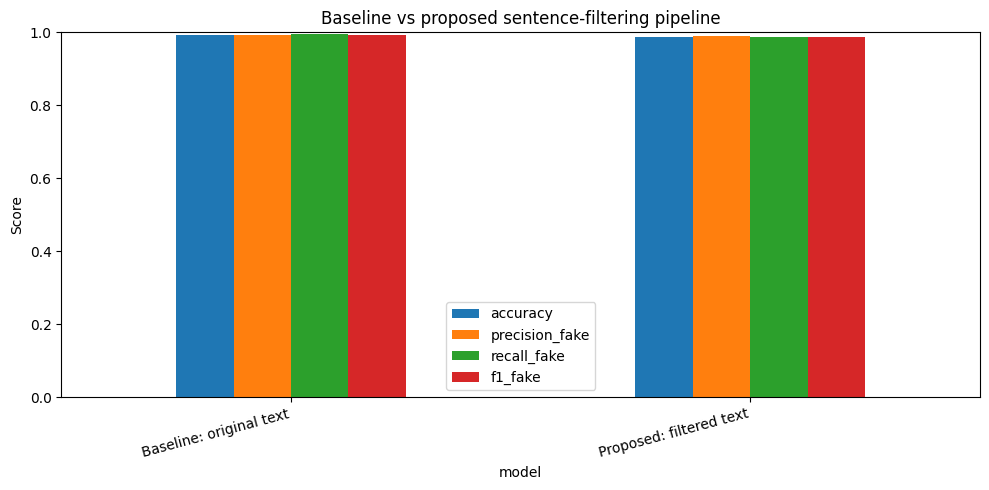

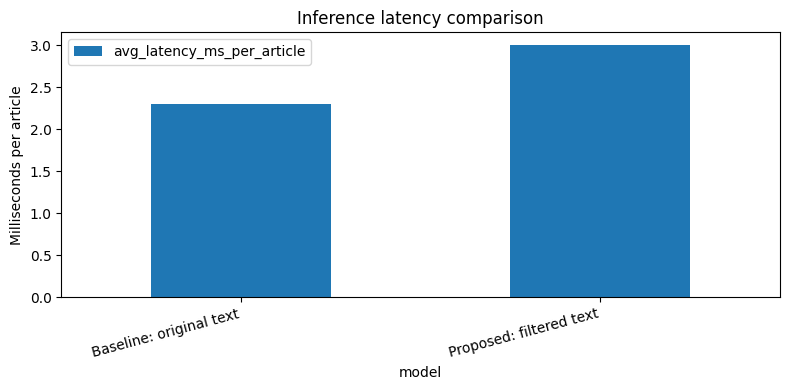

In [ ]:
import matplotlib.pyplot as plt

metric_cols = ["accuracy", "precision_fake", "recall_fake", "f1_fake"]
results.set_index("model")[metric_cols].plot(kind="bar", ylim=(0, 1), figsize=(10, 5))
plt.title("Baseline vs proposed sentence-filtering pipeline")
plt.ylabel("Score")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

results.set_index("model")[["avg_latency_ms_per_article"]].plot(kind="bar", figsize=(8, 4))
plt.title("Inference latency comparison")
plt.ylabel("Milliseconds per article")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
from transformers import pipeline

classifier = pipeline(
    "text-classification",
    model="/content/fake_news_proposed_model",
    tokenizer="/content/fake_news_proposed_model",
    device=0 if torch.cuda.is_available() else -1
)

def predict_news(headline, article_body):
    filtered, keywords, selected = rank_and_filter(headline, article_body)
    prediction = classifier(filtered, truncation=True, max_length=MAX_LENGTH)[0]
    return {
        "prediction": prediction["label"],
        "confidence": round(float(prediction["score"]), 4),
        "keywords": keywords,
        "selected_sentences": selected,
        "text_used_for_classification": filtered
    }

example = predict_news(
    "Example headline goes here",
    "Paste the news article body here. Replace this example with an article you want to test."
)
display(example)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

{'prediction': 'FAKE',
 'confidence': 0.9997,
 'keywords': '',
 'selected_sentences': ['Paste the news article body here.',
  'Replace this example with an article you want to test.'],
 'text_used_for_classification': 'Example headline goes here. Paste the news article body here. Replace this example with an article you want to test.'}

In [ ]:
import os
from google.colab import files

# Zip the processed dataset and experiment results
!zip -r processed_results.zip /content/fake_news_processed.csv /content/experiment_results.csv

# Download the zipped file
files.download('processed_results.zip')

  adding: content/fake_news_processed.csv (deflated 83%)
  adding: content/experiment_results.csv (deflated 35%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
from google.colab import files

file1 = '/content/experiment_results.csv'
file2 = '/content/fake_news_processed.csv'

# Check if the files exist before attempting download
if os.path.exists(file1) and os.path.exists(file2):
    print("Files found! Initiating downloads...")
    files.download(file1)
    files.download(file2)
else:
    print("❌ Files not found.")
    print("Please make sure you have run the preceding training and evaluation cells first to generate 'experiment_results.csv' and 'fake_news_processed.csv'.")

❌ Files not found.
Please make sure you have run the preceding training and evaluation cells first to generate 'experiment_results.csv' and 'fake_news_processed.csv'.
